# 🧔‍♂️🎮👩 Gender Representation in Video Games 👩🎮🧔‍♂️ 

## Context:
These are top-selling or top-rated games, so the numbers describe successful games, not the whole industry.

## Objective: Analizing the representation of women in Videogames. This analyze will be run through the lense of 3 main questions :

| **Q1** | How much more are women sexualized than men, in what ways, and does it depend on the role they play ? 
| **Q2** | What roles do women hold: lead, playable, romantic interest? 
| **Q3** | Good vs. bad: are women allies, antagonists or main villains? 

### Angles that can be added to each question

Each of Q1–Q3 can be re-read through these three lenses:

| **A. Time** | Has it changed over time (2012–2022)? 
| **B. Team mix** | Does the team's gender mix change what is shown?
| **C. Country** | Does the developer's country have an influence? 

# 📥 Data Loading

### 🎯 Goal
Understand what each table contains (size, columns, types, typical values) before cleaning anything.

### 📥 Input
Three CSV files downloaded with `kagglehub` from the Kaggle dataset `br33sa/gender-representation-in-video-games`:

| Table | One row is... | Links to |
|---|---|---|
| `games` | a game | `characters.Game` |
| `characters` | a relevant character | `games.Game_Id`, `sexualization.Id` |
| `sexualization` | the sexualization rating of a character | `characters.Id` |

### 🛠️ What we do
1. Import the libraries (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, `kagglehub`, `os`) and set the plot defaults: `sns.set_style("whitegrid")` and figure size `(10, 6)`.
2. Download the dataset with `kagglehub.dataset_download("br33sa/gender-representation-in-video-games")` and store the folder in `path`.
3. Read each CSV with `pd.read_csv(os.path.join(path, ...))` into `games`, `characters` and `sexualization`.
4. For each table, check `shape`, `columns.tolist()`, `head()` and `info()`.
5. Summarize with `describe()` (numeric columns) and `describe(exclude='number')` (text columns).

### 📝 Observations
*(Fill in after running the code.)*
- e.g. `Unnamed: 27` is completely empty: a column to drop.
- e.g. `Percentage_non_male` and `Team_percentage` are stored as text.
- Full column definitions: `docs/data-dictionary.md`.

## 1. Imports and plot defaults

In [76]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display, Markdown

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2. Download the dataset

In [77]:
path = kagglehub.dataset_download("br33sa/gender-representation-in-video-games")
print("path to files:", path)

Using Colab cache for faster access to the 'gender-representation-in-video-games' dataset.
path to files: /kaggle/input/gender-representation-in-video-games


## 3. Read each CSV

In [78]:
games = pd.read_csv(os.path.join(path, "games.grivg.csv"))
characters = pd.read_csv(os.path.join(path, "characters.grivg.csv"))
sexualization = pd.read_csv(os.path.join(path, "sexualization.grivg.csv"))

tables = {"games": games, "characters": characters, "sexualization": sexualization}

descriptions = {
    "games": "Information about the games. Each row represents a game. Includes genre, development team, and critic reviews.",
    "characters": "Information about the characters. Each row represents a relevant character. Joins with `games` by `Game`.",
    "sexualization": "Information about the sexualization ratings of characters. Each row represents a rating for a character. Joins by `Id`.",
}

## 4. Check structure of each table

In [79]:
for name, d in tables.items():
    display(Markdown(f"#### {name}\n\n{descriptions[name]}"))
    print(f"shape: {d.shape}\n")
    print(f"columns: {d.columns.tolist()}\n")
    display(d.head())
    d.info()
    print("\n")

#### games

Information about the games. Each row represents a game. Includes genre, development team, and critic reviews.

shape: (64, 28)

columns: ['Game_Id', 'Title', 'Release', 'Series', 'Genre', 'Sub-genre', 'Developer', 'Publisher', 'Country', 'Platform', 'PEGI', 'Customizable_main', 'Protagonist', 'Protagonist_Non_Male', 'Relevant_males', 'Relevant_no_males', 'Percentage_non_male', 'Criteria', 'Director', 'Total_team', 'female_team', 'Team_percentage', 'Metacritic ', 'Destructoid', 'IGN', 'GameSpot', 'Avg_Reviews', 'Unnamed: 27']



,Game_Id,Title,Release,Series,Genre,Sub-genre,Developer,Publisher,Country,Platform,...,Director,Total_team,female_team,Team_percentage,Metacritic,Destructoid,IGN,GameSpot,Avg_Reviews,Unnamed: 27
0,GTAV,Grand Theft Auto V,Nov-13,GTA,Action-adventure,Action-adventure,Rockstar North,Rockstar Games,GBR,Multi,...,M,7,0,0%,9.7,9.0,10.0,9.0,9.4,NaN
1,PSS,Pokémon Sword/Shield,Nov-19,Pokémon,RPG,RPG,Game Freak,Nintendo,JPN,Nintendo Switch,...,M,9,1,11%,8.0,7.0,9.3,9.0,8.3,NaN
2,CODMW,Call of Duty: Modern Warfare,Oct-19,Call of Duty,Action,FPS,Infinity Ward,Activision,USA,Multi,...,M,11,0,0%,8.0,8.0,8.0,7.0,7.8,NaN
3,RDR2,Red Dead Redemption 2,Dec-18,Red Dead,Action-adventure,Action-adventure,Rockstar Studios,Rockstar Games,USA,Multi,...,M,7,0,0%,9.7,9.5,10.0,9.0,9.6,NaN
4,SMO,Super Mario Odyssey,Oct-17,Super Mario,Action-adventure,Action-adventure,Nintendo EDP,Nintendo,JPN,Nintendo Switch,...,M,11,1,9%,9.7,9.5,10.0,10.0,9.8,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Game_Id               64 non-null     object 
 1   Title                 64 non-null     object 
 2   Release               64 non-null     object 
 3   Series                27 non-null     object 
 4   Genre                 64 non-null     object 
 5   Sub-genre             64 non-null     object 
 6   Developer             64 non-null     object 
 7   Publisher             64 non-null     object 
 8   Country               64 non-null     object 
 9   Platform              64 non-null     object 
 10  PEGI                  64 non-null     int64  
 11  Customizable_main     64 non-null     object 
 12  Protagonist           64 non-null     int64  
 13  Protagonist_Non_Male  64 non-null     int64  
 14  Relevant_males        64 non-null     int64  
 15  Relevant_no_males     64 

#### characters

Information about the characters. Each row represents a relevant character. Joins with `games` by `Game`.

shape: (637, 12)

columns: ['Name', 'Gender', 'Game', 'Age', 'Age_range', 'Playable', 'Sexualization', 'Id', 'Species', 'Side', 'Relevance', 'Romantic_Interest']



... (2 outputs left out)

#### sexualization

Information about the sexualization ratings of characters. Each row represents a rating for a character. Joins by `Id`.

shape: (637, 6)

columns: ['Id', 'Sexualized_clothing', 'Trophy', 'Damsel in Distress', 'Sexualized Cutscenes', 'Total']



,Id,Sexualized_clothing,Trophy,Damsel in Distress,Sexualized Cutscenes,Total
0,CODMW_Farah,0,0,0,0,0
1,PSS_Protagonist,0,0,0,0,0
2,PSS_Magnolia,0,0,0,0,0
3,PSS_Sonia,0,0,0,0,0
4,PSS_Marnie,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 637 entries, 0 to 636
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Id                    637 non-null    object
 1   Sexualized_clothing   637 non-null    int64 
 2   Trophy                637 non-null    int64 
 3   Damsel in Distress    637 non-null    int64 
 4   Sexualized Cutscenes  637 non-null    int64 
 5   Total                 637 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 30.0+ KB




## 5. Descriptive statistics

In [80]:
for name, d in tables.items():
    display(Markdown(f"#### {name}"))
    display(d.describe())                       # numeric columns
    display(d.describe(exclude="number"))       # text columns

#### games

,PEGI,Protagonist,Protagonist_Non_Male,Relevant_males,Relevant_no_males,Total_team,female_team,Metacritic,Destructoid,IGN,GameSpot,Avg_Reviews,Unnamed: 27
count,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,57.000000,62.000000,62.000000,64.000000,0.0
mean,13.484375,1.250000,0.546875,6.140625,3.812500,6.765625,0.718750,8.906250,9.150877,9.261290,8.840323,9.043750,NaN
std,4.611897,0.590937,0.561452,3.939491,2.635984,3.544467,1.030776,0.440373,0.692594,0.556439,0.763181,0.433837,NaN
min,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,7.900000,7.000000,8.000000,7.000000,7.800000,NaN
25%,7.000000,1.000000,0.000000,3.000000,2.000000,3.750000,0.000000,8.700000,9.000000,9.000000,8.125000,8.700000,NaN
50%,16.000000,1.000000,1.000000,6.000000,4.000000,7.000000,0.000000,8.900000,9.000000,9.300000,9.000000,9.000000,NaN
75%,18.000000,1.000000,1.000000,8.250000,5.000000,9.000000,1.000000,9.200000,9.500000,9.600000,9.000000,9.325000,NaN
max,18.000000,4.000000,2.000000,17.000000,14.000000,16.000000,4.000000,9.700000,10.000000,10.000000,10.000000,9.900000,NaN


,Game_Id,Title,Release,Series,Genre,Sub-genre,Developer,Publisher,Country,Platform,Customizable_main,Percentage_non_male,Criteria,Director,Team_percentage
count,64,64,64,27,64,64,64,64,64,64,64,64,64,64,64
unique,64,64,50,25,6,21,54,44,13,8,3,35,3,2,18
top,GTAV,Grand Theft Auto V,Mar-15,Pokémon,Action-adventure,Action-adventure,FromSoftware,Nintendo,USA,Multi,No,33%,TR,M,0%
freq,1,1,3,2,21,16,4,6,24,47,49,5,53,62,36


#### characters

,Playable,Sexualization
count,637.000000,637.000000
mean,0.193093,0.086342
std,0.395035,0.389022
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,3.000000


,Name,Gender,Game,Age,Age_range,Id,Species,Side,Relevance,Romantic_Interest
count,637,637,637,637,637,637,637,637,637,637
unique,616,4,64,59,8,637,10,3,6,3
top,Protagonist,Male,IWATE,Adult,Adult,CODMW_Farah,Human,P,SC,No
freq,4,393,27,231,264,1,482,426,266,589


#### sexualization

,Sexualized_clothing,Trophy,Damsel in Distress,Sexualized Cutscenes,Total
count,637.000000,637.000000,637.000000,637.000000,637.000000
mean,0.029827,0.010989,0.028257,0.017268,0.086342
std,0.170244,0.104333,0.165838,0.130372,0.389022
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,3.000000


,Id
count,637
unique,637
top,CODMW_Farah
freq,1


# 🔍 Exploración

> We look for problems in the data (missing values, duplicates, outliers, inconsistencies).

---

### 🎯 Goal
Find what needs cleaning before changing anything. Studying the variables comes later, in *Análisis*, once the tables are clean.

### 📥 Input
The three tables loaded in *Carga* (`games`, `characters`, `sexualization`), still unmodified.

### 🛠️ What we do
1. **Missing values:** count nulls per column (`df.isnull().sum()`) and show the percentage (`nulls / len(df) * 100`), only for columns above 0. Optional: `missingno` matrix.
2. **Duplicates:** `df.duplicated().sum()`.
3. **Outliers:** IQR rule, flagged outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`, plus boxplots.
4. **Dubious data:** check consistency between columns (e.g. `characters.Sexualization` vs `sexualization.Total`) and impossible values (e.g. ages).

### 📊 Charts checklist
Every chart has a title, named axes, and a legend when it has more than one series. Minimum **5 visualizations** in total.

### 📝 Observations and decisions
*(Fill in after running the code. Nothing is changed in this section: decisions are applied in *Limpieza*.)*

| Finding | Where | What we will do | Why |
|---|---|---|---|
| *(e.g. `Series` has 58% nulls)* | `games` | *(keep / fill / drop)* | *(reason)* |
| *(e.g. outlier in `Total_team`)* | `games` | *(keep / cap / drop)* | *(reason)* |

## 1. Missing values

#### games

,missing,percent
Unnamed: 27,64,100.0
Series,37,57.8
Destructoid,7,10.9
IGN,2,3.1
GameSpot,2,3.1


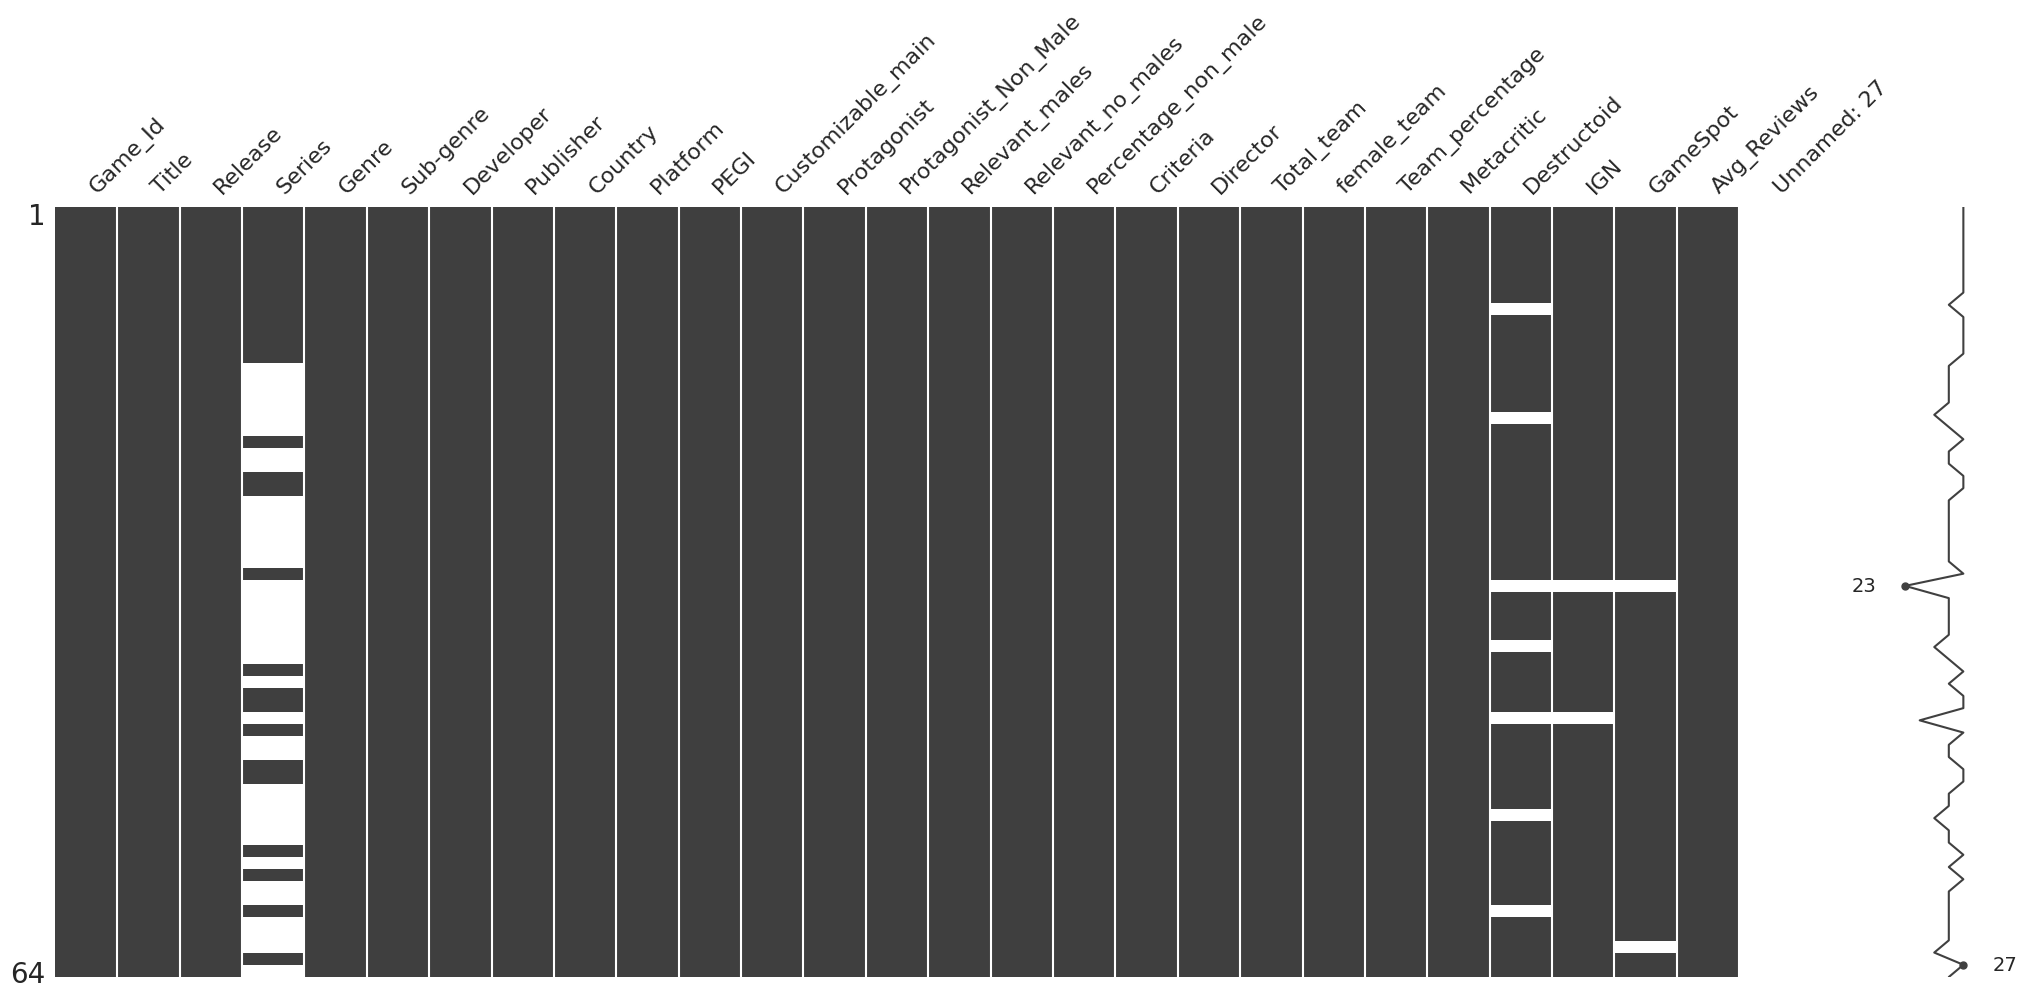

#### characters

No missing values.



#### sexualization

No missing values.



In [81]:
import missingno as msno

for name, d in tables.items():
    display(Markdown(f"#### {name}"))

    nulls = d.isnull().sum()
    nulls = nulls[nulls > 0]

    if nulls.empty:
        print("No missing values.\n")
        continue

    report = pd.DataFrame({
        "missing": nulls,
        "percent": (nulls / len(d) * 100).round(1),
    }).sort_values("percent", ascending=False)
    display(report)

    msno.matrix(d)
    plt.show()



## 2. Duplicates

In [82]:
for name, d in tables.items():
    display(Markdown(f"#### {name}"))
    n_duplicates = d.duplicated().sum()

    if n_duplicates == 0:
        print("No duplicates found.\n")
        continue

    print(f"{n_duplicates} duplicated row(s):")
    display(d[d.duplicated(keep=False)]) 
    tables[name] = d.drop_duplicates()

#### games

No duplicates found.



#### characters

No duplicates found.



#### sexualization

No duplicates found.



## 3. Outliers

> 🚧 **Draft.** First pass on `Team_percentage` (boxplot in *Análisis*). To be completed (IQR on every numeric variable, final decisions).

### Team_percentage (share of women in the development team)

**Method:** IQR rule on the boxplot. A value is an outlier if it lies outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

**Findings**<br>
- Q1 = 0%, median = 0%, Q3 = 14.75%, so IQR = 14.75 and the upper fence is about 36.9%.
- 5 of the 64 games lie above it: 43%, 50%, 60% and two at 67%.
- The distribution is strongly right-skewed (skewness ≈ 1.9): 36 of the 64 games (56%) have exactly 0% women in the team, and the mean (10.7%) is far above the median (0%).

⚖️ **Decision (provisional):** keep the 5 outlier games.<br>
**Why:** they are not data errors. They are real games with unusually balanced teams, and they are the most interesting cases for the team-mix question. Removing them would also leave only 59 games in a dataset that is already small.

⚠️ **Caution:** because the box is squashed at 0, the IQR rule flags a lot relative to the typical value. The mean is misleading here, so we use the median.

### Avg_Reviews
*(to fill in: outliers seen on the boxplot, and decision)*

### To revisit
- Check the other numeric variables (`Total_team`, `Protagonist`, `Percentage_non_male`, `Age`...).
- Confirm the decision on `Team_percentage` once we run angle B (see Q1–Q3 add-ons).

## 4. Dubious data

### Columns Metacritic, Destructoid, IGN, GameSpot and Avg_Reviews
Column "Avg_Reviews" which is supposed to be the average of the 4 review scores ("Metacritic ", "Destructoid", "IGN", "GameSpot")
We could consider dropping the 4 review score columns if Avg_Reviews is reliable.

In [66]:
# First checking how Avg_Reviews was computed.

scores = ["Metacritic ", "Destructoid", "IGN", "GameSpot"]   # note the trailing space in "Metacritic "
recomputed = games[scores].mean(axis=1).round(1)
print("Games where Avg_Reviews differs from the recomputed mean:",
      (recomputed != games["Avg_Reviews"]).sum())


Games where Avg_Reviews differs from the recomputed mean: 8


In [67]:
# checking the distribution of the differences

diff = (recomputed - games["Avg_Reviews"]).round(2)
mismatch = games.loc[diff != 0, ["Title"] + scores + ["Avg_Reviews"]].copy()
mismatch["recomputed"] = recomputed[diff != 0]
mismatch["diff"] = diff[diff != 0]
display(mismatch)

,Title,Metacritic,Destructoid,IGN,GameSpot,Avg_Reviews,recomputed,diff
12,Uncharted 4: A Thief's End,9.3,9.5,9.0,10.0,9.5,9.4,-0.1
23,Persona 5,9.5,9.0,9.8,9.5,9.5,9.4,-0.1
29,Deathloop,8.8,9.0,10.0,10.0,9.5,9.4,-0.1
32,Immortality,8.8,9.0,8.0,8.0,8.5,8.4,-0.1
40,Dragon Quest XI,8.8,8.0,8.8,9.0,8.7,8.6,-0.1
53,Bayonetta 2,9.1,10.0,9.5,10.0,9.7,9.6,-0.1
57,Owlboy,8.7,10.0,9.3,9.0,9.3,9.2,-0.1
59,The Binding of Isaac: Rebirth,8.4,10.0,9.0,8.0,8.9,8.8,-0.1


**Findings**<br>

8 games differ by 0.1, and in all 8 the exact mean ends in 5 (e.g. 9.45), so the source rounds up and Python rounds down. 

It is only a rounding difference, so `Avg_Reviews` is reliable. The other columns can be dropped in the cleaning section

### Sexualization table
Column "Total" from Sexialization table is supposed to be the average of the 4 other columns ("Sexualized_clothing", "Trophy", "Damsel in Distress", "Sexualized Cutscenes")
We should make sure "Total" is reliable before using it in the analyze.

In [68]:
sex = tables["sexualization"]
chars = tables["characters"]
criteria = ["Sexualized_clothing", "Trophy", "Damsel in Distress", "Sexualized Cutscenes"]

#Every criterion must be 0 or 1
print("Values outside {0,1}:", (~sex[criteria].isin([0, 1])).sum().sum())

#Total must equal the sum of the four criteria
print("Total != sum of criteria:", (sex["Total"] != sex[criteria].sum(axis=1)).sum())

#characters.Sexualization must equal sexualization.Total
merged = chars.merge(sex, on="Id", how="outer", indicator=True)
print("Ids missing in one table:", (merged["_merge"] != "both").sum())
print("Sexualization != Total:", (merged["Sexualization"] != merged["Total"]).sum())

#Metadata rule: a child or infant is never a "damsel in distress"
display(merged.query("Age_range in ['Child', 'Infant'] and `Damsel in Distress` == 1")
              [["Name", "Game", "Age_range", "Damsel in Distress", "Total"]])

games_c = tables["games"]

Values outside {0,1}: 0
Total != sum of criteria: 0
Ids missing in one table: 0
Sexualization != Total: 0


,Name,Game,Age_range,Damsel in Distress,Total
412,Son,PP,Child,1,1


**Findings**<br> 

Checks 1 to 3 all give 0, so the tables are fully consistent. 

Check 4 finds 1 real inconsistency: the character Son (game PP, a Child) has Damsel_in_distress = 1, which contradicts the author's own rule. (Children are expected to require assistance and are therefore not considered as "Damsel in distress") 

It's 1 of 637 rows, so it won't change the results, but it should be cleaned.

### Age vs Age_range
The numeric ages must fall inside their category

In [69]:
age = pd.to_numeric(chars["Age"], errors="coerce")
labels = ["Infant", "Child", "Teenager", "Young adult", "Adult", "Middle-aged", "Elderly"]
expected = pd.cut(age, bins=[0, 6, 15, 18, 25, 40, 65, np.inf], right=False, labels=labels).astype(str)
print("Age outside its Age_range:", (age.notnull() & (expected != chars["Age_range"])).sum())

Age outside its Age_range: 0


### Team_percentage 
Team_percentage must match Female_team / Total_team

In [70]:
pct = games_c["Team_percentage"].str.rstrip("%").astype(float)
print("Team_percentage off by more than 1 point:",
      ((pct - games_c["female_team"] / games_c["Total_team"] * 100).abs() > 1).sum())

Team_percentage off by more than 1 point: 0


# 🧹 Data Cleaning

> We turn the raw tables into clean, analysis-ready ones: fixing types, filling or dropping gaps, removing columns we don't need and giving columns consistent names.

---

### 🎯 Goal
Apply the decisions taken in *Exploración*, so the analysis starts from tidy tables. Every change is explained (what we did and why) and the raw tables stay untouched.

### 📥 Input
The three tables from *Carga* (`games`, `characters`, `sexualization`) and the problems found in *Exploración* (empty column, gaps in `Series`, text values in numeric columns, inconsistent names).

### 🛠️ What we do
1. **Remove empty or useless columns:** `Unnamed: 27` (empty) and the columns no question uses (`Sub-genre`, `Publisher`, `Platform`, `PEGI`, `Criteria`).
2. **Keep one review score:** keep `Avg_Reviews` and drop the four individual scores (`Metacritic`, `Destructoid`, `IGN`, `GameSpot`), once we verified it is reliable.
3. **Fill gaps with meaning:** `Series` → `"Standalone"` (a missing value means "no series").
4. **Rename columns** to one consistent style (`Female_team`, `Damsel_in_distress`, `Sexualized_cutscenes`).
5. **Fix data types:** `Release` text (`Nov-13`) → date and year; `Percentage_non_male` and `Team_percentage` (`"11%"`) → numbers; `Age` (numbers and words) → numeric where possible.
6. **Create new variables** (at least 3), for example `Release_year`, a female-lead flag, and groups of countries.
7. **Check the result:** `info()` on the clean tables, and no missing value left unexplained.

### 🔎 Rules we follow
| Situation | Treatment |
|---|---|
| A blank means "does not apply" (e.g. no series) | Fill with a label |
| A numeric value is truly unknown | Leave as `NaN`, never a text label |
| A column is empty or not used by any question | Drop it, with the reason |
| Two columns hold the same information | Keep one, after checking they match |

### 📝 Decisions
Each decision is written next to the code that applies it, as **what we did + why**.

### ✅ Result
*(Fill in after running the code.)*
- Clean tables: `games_clean`, `characters_clean`, `sexualization_clean`.
- Columns before → after, per table.

Notes:
- Steps 5 and 6 haven't been done in your notebook yet (the types and the new variables are tasks #3 and #14). Remove them from the list for now if you'd rather document only what is finished, or keep them as the plan and fill them in later.
- The "Rules we follow" table is only a summary of the principles you already applied. Delete it if you prefer the section shorter.
- Your current notebook does part of this work (the drops, the Series fill) inside Exploración. If you want the structure to match, move those cells under this Limpieza heading. Then Exploración only finds problems, and Limpieza only fixes them.

## 1. Remove empty or useless columns:

⚖️ **Decision:** drop `Unnamed: 27` from `games`. <br>
    **Why:** the column is completely empty. It comes from a trailing comma at the end of every row in the CSV, so it holds no information.

In [71]:
games = games.drop(columns=["Unnamed: 27"], errors="ignore")
tables["games"] = games

⚖️ **Decision:** drop `Sub-genre`, `Publisher`, `Platform`, `PEGI` and `Criteria`.<br>
    **Why:** none of our three questions or their angles (time, team mix, country) uses them.

In [72]:
cols_to_drop = [
    "Unnamed: 27", "Sub-genre", "Publisher", "Platform", "PEGI", "Criteria",
]

games_clean = games.drop(columns=cols_to_drop, errors="ignore")
tables["games"] = games_clean
print(games_clean.columns.tolist())

['Game_Id', 'Title', 'Release', 'Series', 'Genre', 'Developer', 'Country', 'Customizable_main', 'Protagonist', 'Protagonist_Non_Male', 'Relevant_males', 'Relevant_no_males', 'Percentage_non_male', 'Director', 'Total_team', 'female_team', 'Team_percentage', 'Metacritic ', 'Destructoid', 'IGN', 'GameSpot', 'Avg_Reviews']


## 2. Keep one review score

⚖️ **Decision:** drop `Metacritic`, `Destructoid`, `IGN`, and `GameSpot`. Keep `Avg_Reviews`<br>
    **Why:** `Avg_Reviews` is the average of the four scores and has no gaps, while the individual scores have missing values. 
    
    `Avg_Reviews` has been found reliable in previous investigation.

In [73]:
cols_to_drop = [
    "Metacritic ", "Destructoid", "IGN", "GameSpot",
]

games_clean = games.drop(columns=cols_to_drop, errors="ignore")
tables["games"] = games_clean
print(games_clean.columns.tolist())

['Game_Id', 'Title', 'Release', 'Series', 'Genre', 'Sub-genre', 'Developer', 'Publisher', 'Country', 'Platform', 'PEGI', 'Customizable_main', 'Protagonist', 'Protagonist_Non_Male', 'Relevant_males', 'Relevant_no_males', 'Percentage_non_male', 'Criteria', 'Director', 'Total_team', 'female_team', 'Team_percentage', 'Avg_Reviews']


## 3. Fill gaps with meaning

⚖️ **Decision: fill the missing values of `Series` with `"Standalone"`.**<br>

    **Why:** a missing value here does not mean "unknown", it means the game belongs to no series. A label keeps these 37 games (58%) in `groupby` and charts, which ignore NaN by default.

In [74]:
# Series: a missing value means the game belongs to no series, so we label it
games["Series"] = games["Series"].fillna("Standalone")
tables["games"] = games 

# Check: no missing values left in those columns
print("Missing in Series:", games["Series"].isnull().sum())
print(games["Series"].value_counts().head(), "\n")


Missing in Series: 0
Series
Standalone      37
Pokémon          2
Call of Duty     2
GTA              1
Super Mario      1
Name: count, dtype: int64 



## 4. Rename columns

⚖️ **Decision:** Renaming columns whose name has a space, a hyphen, or does not start with a capital letter .<br>

    **Why:** Having a consistent naming convention. No other renaming seems necessary.

In [75]:
# Finding columns whose name has a space, a hyphen, or does not start with a capital letter

for name, d in tables.items():
    bad = [c for c in d.columns if c != c.strip() or " " in c or "-" in c or not c[0].isupper()]
    print(f"{name}: {bad if bad else 'names OK'}")
    
rename_map = {
    "games": {"female_team": "Female_team"},
    "sexualization": {
        "Damsel in Distress": "Damsel_in_distress",
        "Sexualized Cutscenes": "Sexualized_cutscenes",
    },
}

for name, mapping in rename_map.items():
    tables[name] = tables[name].rename(columns=mapping)

print(tables["sexualization"].columns.tolist())

d.columns.tolist()
d.head()

games: ['Sub-genre', 'female_team', 'Metacritic ']
characters: names OK
sexualization: ['Damsel in Distress', 'Sexualized Cutscenes']
['Id', 'Sexualized_clothing', 'Trophy', 'Damsel_in_distress', 'Sexualized_cutscenes', 'Total']


,Id,Sexualized_clothing,Trophy,Damsel in Distress,Sexualized Cutscenes,Total
0,CODMW_Farah,0,0,0,0,0
1,PSS_Protagonist,0,0,0,0,0
2,PSS_Magnolia,0,0,0,0,0
3,PSS_Sonia,0,0,0,0,0
4,PSS_Marnie,0,0,0,0,0


# 📊 Análisis

> With clean tables, we study the variables alone (univariate) and in pairs (bivariate) to answer Q1–Q3.

---

### 🎯 Goal
Describe each variable we need, then compare groups (mainly women vs men) to answer our three questions.

### 📥 Input
The clean tables from *Limpieza* (`games`, `characters`, `sexualization`).

### 🛠️ What we do
1. **Univariate analysis** (at least 3 variables):
   - categorical (e.g. `Gender`, `Relevance`) → bar chart of `value_counts()`
   - numeric (e.g. `Team_percentage`) → histogram + boxplot
2. **Bivariate analysis** (at least 3 relationships):
   - category vs category → `pd.crosstab(..., normalize="index") * 100` + grouped bars (e.g. `Gender` × `Sexualization`)
   - number vs category → boxplot by group
3. Show `n` next to every percentage: the dataset is small.

### 📊 Charts checklist
Every chart has a title, named axes, and a legend when it has more than one series.


## 1. Univariate analysis

### Gender Variable from Characters table

,n,percent
Gender,,
Male,393,61.7
Female,203,31.9
Non-binary,33,5.2
Custom,8,1.3


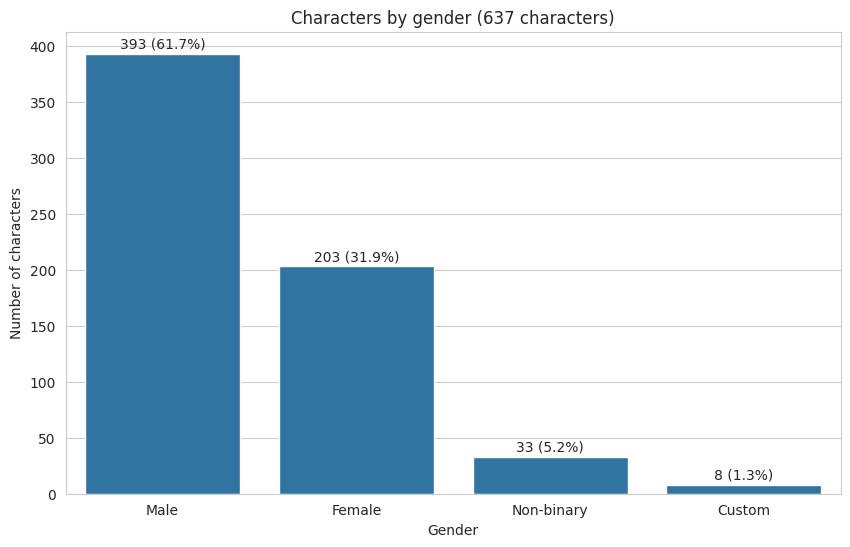

In [84]:
characters = tables["characters"]

# 1. The numbers
counts = characters["Gender"].value_counts()
summary = pd.DataFrame({
    "n": counts,
    "percent": (counts / len(characters) * 100).round(1),
})
display(summary)

# 2. Bar chart
fig, ax = plt.subplots()
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_title("Characters by gender (637 characters)")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of characters")

# write "n (percent)" above each bar
for i, n in enumerate(counts.values):
    ax.text(i, n + 5, f"{n} ({n / len(characters) * 100:.1f}%)", ha="center")

plt.show()

**Findings**<br>

- men are about 62% of characters (393 of 637) and women about 32% (203). So there are roughly two men for every woman.
- Non-binary and Custom are smaller groups (33 and 8) 

### Team percentage from Games table

The column `Team_percentage` is stored as text with a "%" sign ("0%", "11%"). Pandas can't draw a histogram of that. 
For the purpose of Data Exploration, we will do the conversion inside this cell for now. 
We will do a proper cleaning of this variavle in the Cleaning section.

count    64.000000
mean     10.734375
std      16.845933
min       0.000000
25%       0.000000
50%       0.000000
75%      14.750000
max      67.000000
Name: Team_percentage, dtype: float64
Median: 0.0
Skewness: 1.94
Games with 0%: 36 (56%)


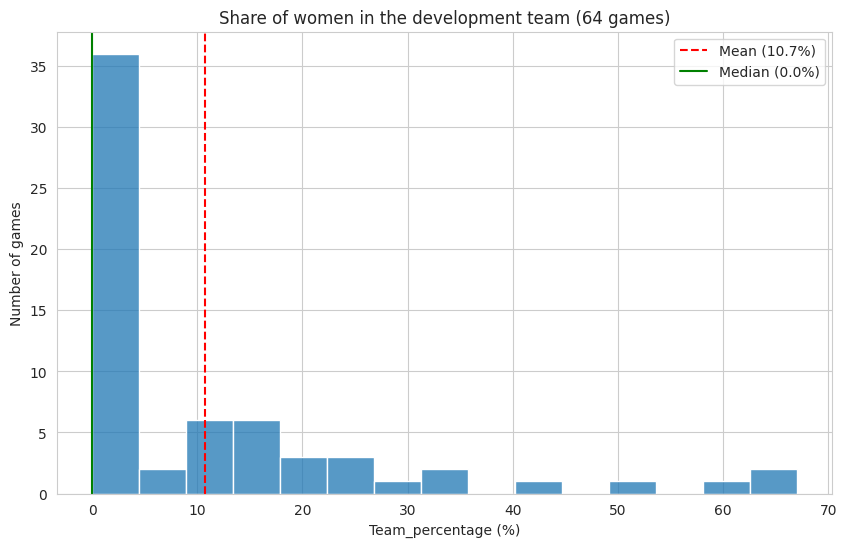

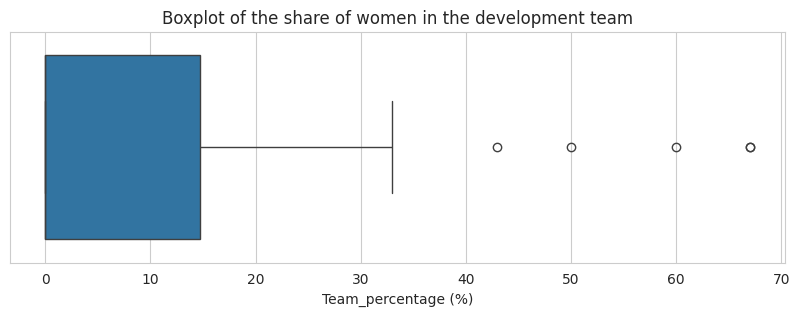

In [85]:
games = tables["games"]

# Convert "11%" -> 11.0
team_pct = games["Team_percentage"].str.rstrip("%").astype(float)

# 1. The numbers
print(team_pct.describe())
print("Median:", team_pct.median())
print("Skewness:", round(team_pct.skew(), 2))
print("Games with 0%:", (team_pct == 0).sum(), f"({(team_pct == 0).mean() * 100:.0f}%)")

# 2. Histogram
fig, ax = plt.subplots()
sns.histplot(team_pct, bins=15, ax=ax)
ax.axvline(team_pct.mean(), color="red", linestyle="--", label=f"Mean ({team_pct.mean():.1f}%)")
ax.axvline(team_pct.median(), color="green", linestyle="-", label=f"Median ({team_pct.median():.1f}%)")
ax.set_title("Share of women in the development team (64 games)")
ax.set_xlabel("Team_percentage (%)")
ax.set_ylabel("Number of games")
ax.legend()
plt.show()

# 3. Boxplot
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=team_pct, ax=ax)
ax.set_title("Boxplot of the share of women in the development team")
ax.set_xlabel("Team_percentage (%)")
plt.show()

**Findings**<br>

- Mean vs. median: the mean (10.7) is well above the median (0). This gap is the sign of a skewed distribution, and a few high values are pulling the mean up.

- Histogram: one tall bar at 0 and a long tail to the right.

- Boxplot: the box is squashed at 0 because 25% and 50% are both 0 and the 75% mark is only 14.75. The dots on the right (43, 50, 60, 67, 67) are flagged as outliers by the IQR rule.

- The typical game in this dataset has no women in its core team, and the mean misleads here, so we will prefer the median.

### Roles from characters

,role,n,percent
Relevance,,,
SC,Secondary character,266,41.8
MC,Main character,202,31.7
PA,Protagonist,80,12.6
MA,Main antagonist,53,8.3
DA,Deuteragonist,18,2.8
SK,Sidekick,18,2.8


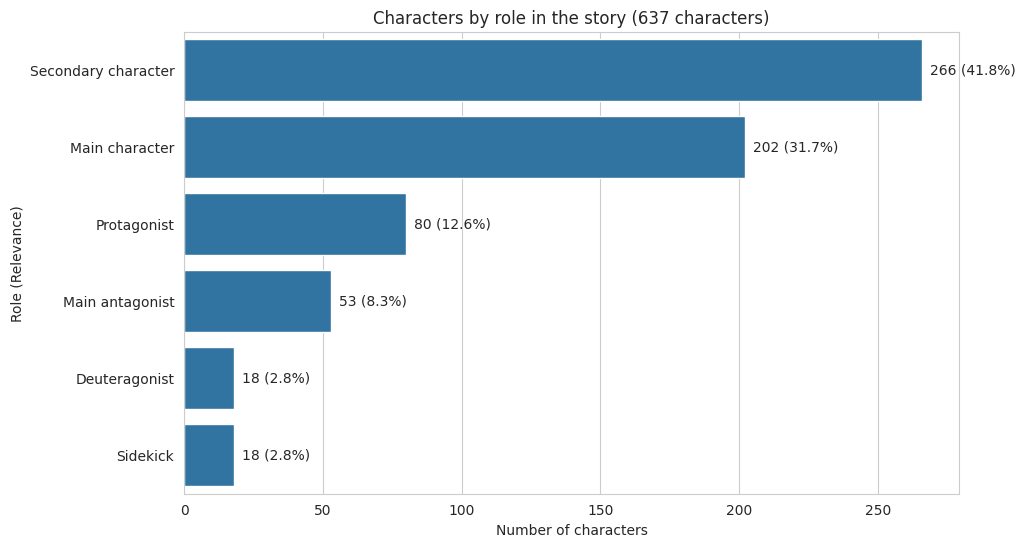

In [87]:
characters = tables["characters"]

role_labels = {
    "PA": "Protagonist",
    "DA": "Deuteragonist",
    "SK": "Sidekick",
    "MC": "Main character",
    "SC": "Secondary character",
    "MA": "Main antagonist",
}

# 1. The numbers
counts = characters["Relevance"].value_counts()
summary = pd.DataFrame({
    "role": counts.index.map(role_labels),
    "n": counts.values,
    "percent": (counts.values / len(characters) * 100).round(1),
}, index=counts.index)
display(summary)

# 2. Bar chart (sorted from most to least frequent)
fig, ax = plt.subplots()
sns.barplot(x=counts.values, y=counts.index.map(role_labels), ax=ax)
ax.set_title("Characters by role in the story (637 characters)")
ax.set_xlabel("Number of characters")
ax.set_ylabel("Role (Relevance)")

for i, n in enumerate(counts.values):
    ax.text(n + 3, i, f"{n} ({n / len(characters) * 100:.1f}%)", va="center")

plt.show()

**Findings**<br>

- The majority are background: secondary characters are about 42% (266 of 637). Main characters are another 32%.

- Protagonists are rare: 80 characters, about 13%. 


## 2. Bivariate analysis

# OTHER

- **Angle B and `Team_percentage` is heavily skewed.** 36 of the 64 games (56%) have exactly 0% women in the team, and the median is 0%. Correlating or averaging the raw percentage is therefore misleading. Instead, compare two groups: games with **0%** vs games with **>0%** (n = 36 vs 28), and show `n` for both. If the >0% group is still informative, it can be split further (for example, 1–25% and >25%).